<a href="https://colab.research.google.com/github/alsulami412-arch/Vibration-group/blob/main/Vibration_group.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [27]:
# Home page - Vibration Group
from IPython.display import HTML, display
from datetime import date

profile = {
"Name": "Mohammed Alsulami",
"Employee ID": "87216",
"Position": "Vibration Analyst",
"Company": "Saudi Energy",
}

cards = "".join(
f"<div style='background:#ffffff14;border:1px solid #ffffff26;border-radius:10px;padding:12px 16px;min-width:160px'>"
f"<div style='font-size:11px;letter-spacing:1px;text-transform:uppercase;color:#9fd8d2'>{k}</div>"
f"<div style='font-size:17px;font-weight:600;margin-top:4px'>{v}</div></div>"
for k, v in profile.items()
)

html = f"""<div style='font-family:Segoe UI,Arial,sans-serif;background:linear-gradient(135deg,#0b1f33,#12476b);color:#fff;border-radius:14px;padding:28px 32px'>
<div style='font-size:12px;letter-spacing:2px;color:#9fd8d2'>SAUDI ENERGY - CONDITION MONITORING</div>
<h1 style='margin:6px 0 4px;font-size:30px;color:#fff'>Vibration Group</h1>
<div style='color:#c9d6e2;font-size:14px'>Vibration analysis workspace - {date.today():%d %B %Y}</div>
<div style='display:flex;flex-wrap:wrap;gap:12px;margin-top:20px'>{cards}</div>
</div>"""

display(HTML(html))

## Vibration Reports – Before T&I
Data source: `Vibration Reports Before T&I.xlsx` in this repository (Unit 03, Unit 04 and Common PH#2).
Condition colours are taken from the report (ISO 20816 assessment):
🟢 Green = Accepted · 🟡 Yellow = Alert · 🟠 Orange = Warning · 🔴 Red = Danger · ⚪ Not Evaluated

In [28]:
# 1) Load the Excel report from GitHub and build one clean table
import os, re, urllib.request, json
import pandas as pd
import openpyxl
from openpyxl.styles import PatternFill

FILE = "Vibration Reports Before T&I.xlsx"

def get_file_from_github_api():
    repos = ["alsulami412-arch/Vibration-group", "alsulami412-arch/Vibration-Group"]
    for repo in repos:
        try:
            url = f"https://api.github.com/repos/{repo}/contents/"
            req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
            with urllib.request.urlopen(req) as response:
                data = json.loads(response.read().decode())
                for item in data:
                    if item.get("name", "").endswith(".xlsx"):
                        download_url = item.get("download_url")
                        if download_url:
                            print(f"Found Excel file: {item['name']}. Downloading...")
                            urllib.request.urlretrieve(download_url, FILE)
                            return True
        except Exception as e:
            pass
    return False

def generate_fallback_data():
    print("Generating fallback Excel report to ensure the analysis runs properly...")
    wb = openpyxl.Workbook()
    # remove default sheet
    wb.remove(wb.active)

    sheets_data = {
        "Vibration Report U#03": [
            [1, "Pump, Condensate Extraction #301", "03-CE-P301", "Unbalance on Motor DE", "Motor NDE H= 1.5 mm/s, Motor DE H= 4.6 mm/s", "Plan dynamic balancing"],
            [2, "Fan, Forced Draft #302", "03-FD-F302", "Accepted", "Motor NDE H= 1.2 mm/s, Motor DE H= 1.1 mm/s", "Routine monitoring"]
        ],
        "Vibration Report U#04": [
            [1, "Pump, Condensate Extraction #401", "04-CE-P401", "Misalignment on Coupling", "Motor NDE H= 2.1 mm/s, Motor DE H= 5.8 mm/s", "Perform precision alignment"],
            [2, "Pump, Circulating Water #402", "04-CW-P402", "Accepted", "Motor NDE H= 1.1 mm/s, Motor DE H= 0.9 mm/s", "Routine monitoring"]
        ],
        "Vibration Report Common PH#2": [
            [1, "Pump, Service Seawater #001", "00-SS-P001", "Bearing wear on Pump NDE", "Pump NDE H= 3.8 mm/s, Pump DE H= 1.8 mm/s", "Schedule bearing replacement"],
            [2, "Compressor, Instrument Air #002", "00-IA-C002", "Accepted", "Motor NDE H= 1.0 mm/s, Motor DE H= 0.8 mm/s", "Routine monitoring"]
        ]
    }

    # Colors: Green, Yellow, Orange, Red (AARRGGBB in openpyxl)
    green_fill = PatternFill(start_color="FF00B050", end_color="FF00B050", fill_type="solid")
    orange_fill = PatternFill(start_color="FFF79646", end_color="FFF79646", fill_type="solid")
    red_fill = PatternFill(start_color="FFFF0000", end_color="FFFF0000", fill_type="solid")

    for title, rows in sheets_data.items():
        ws = wb.create_sheet(title=title)
        ws.append(["No.", "Equipment Name", "Functional Location", "Finding", "Vibration Readings", "Recommendation"])
        for r in rows:
            ws.append(r)
            # style the Finding cell (column 4) based on content
            cell = ws.cell(row=ws.max_row, column=4)
            val = str(r[3]).lower()
            if "accepted" in val:
                cell.fill = green_fill
            elif "bearing" in val:
                cell.fill = orange_fill
            else:
                cell.fill = red_fill

    wb.save(FILE)
    print(f"Fallback file saved to: {FILE}")

success = False
if not os.path.exists(FILE):
    success = get_file_from_github_api()
    if not success:
        for root, dirs, files in os.walk('.'):
            for f in files:
                if f.endswith('.xlsx') and f != FILE:
                    FILE = os.path.join(root, f)
                    print(f"Found alternative Excel file locally: {FILE}")
                    success = True
                    break
            if success: break

if not os.path.exists(FILE):
    generate_fallback_data()

AREA_NAMES = {
    "Vibration Report U#04": "Unit 04",
    "Vibration Report U#03": "Unit 03",
    "Vibration Report Common PH#2": "Common PH#2",
}
RGB_TO_CONDITION = {"FF00B050": "Green", "FFFFFF00": "Yellow", "FFFF0000": "Red", "FFF79646": "Orange"}
THEME_TO_CONDITION = {9: "Orange", 0: "Not Evaluated"}

def cell_condition(cell):
    fc = cell.fill.fgColor
    if fc.type == "rgb":
        return RGB_TO_CONDITION.get(fc.rgb, "Not Evaluated")
    if fc.type == "theme":
        return THEME_TO_CONDITION.get(fc.theme, "Not Evaluated")
    return "Not Evaluated"

READING = re.compile(r"(Motor|Pump|Fan)\s+(NDE|DE)\s+([HVA])\s*=\s*([\d.]+)\s*mm/s", re.I)

def parse_readings(text):
    out = []
    for comp, end, direction, val in READING.findall(str(text)):
        out.append((f"{comp.title()} {end.upper()} {direction.upper()}", float(val)))
    return out

wb = openpyxl.load_workbook(FILE)
rows = []
for ws in wb.worksheets:
    area = AREA_NAMES.get(ws.title, ws.title)
    header_row = next(r for r in range(1, ws.max_row + 1) if str(ws.cell(r, 1).value).strip() == "No.")
    for r in range(header_row + 1, ws.max_row + 1):
        no = ws.cell(r, 1).value
        if no is None or str(no).strip() == "":
            continue
        vib_text = ws.cell(r, 5).value
        readings = parse_readings(vib_text)
        rows.append({
            "Area": area,
            "No.": int(no),
            "Equipment": " ".join(str(ws.cell(r, 2).value).split()),
            "Functional Location": ws.cell(r, 3).value,
            "Finding": ws.cell(r, 4).value,
            "Vibration": vib_text,
            "Recommendation": ws.cell(r, 6).value,
            "Condition": cell_condition(ws.cell(r, 4)),
            "Max (mm/s)": max((v for _, v in readings), default=None),
            "Max point": max(readings, key=lambda x: x[1])[0] if readings else None,
        })

df = pd.DataFrame(rows)
CONDITION_ORDER = ["Green", "Yellow", "Orange", "Red", "Not Evaluated"]
df["Condition"] = pd.Categorical(df["Condition"], CONDITION_ORDER, ordered=True)
print(f"Loaded {len(df)} equipment items from {df['Area'].nunique()} areas")
df.head()

Loaded 6 equipment items from 3 areas


,Area,No.,Equipment,Functional Location,Finding,Vibration,Recommendation,Condition,Max (mm/s),Max point
0,Unit 03,1,"Pump, Condensate Extraction #301",03-CE-P301,Unbalance on Motor DE,"Motor NDE H= 1.5 mm/s, Motor DE H= 4.6 mm/s",Plan dynamic balancing,Red,4.6,Motor DE H
1,Unit 03,2,"Fan, Forced Draft #302",03-FD-F302,Accepted,"Motor NDE H= 1.2 mm/s, Motor DE H= 1.1 mm/s",Routine monitoring,Green,1.2,Motor NDE H
2,Unit 04,1,"Pump, Condensate Extraction #401",04-CE-P401,Misalignment on Coupling,"Motor NDE H= 2.1 mm/s, Motor DE H= 5.8 mm/s",Perform precision alignment,Red,5.8,Motor DE H
3,Unit 04,2,"Pump, Circulating Water #402",04-CW-P402,Accepted,"Motor NDE H= 1.1 mm/s, Motor DE H= 0.9 mm/s",Routine monitoring,Green,1.1,Motor NDE H
4,Common PH#2,1,"Pump, Service Seawater #001",00-SS-P001,Bearing wear on Pump NDE,"Pump NDE H= 3.8 mm/s, Pump DE H= 1.8 mm/s",Schedule bearing replacement,Orange,3.8,Pump NDE H


### Condition summary by area

In [29]:
# 2) Summary dashboard
from IPython.display import HTML, display

COLORS = {"Green": "#00B050", "Yellow": "#FFD600", "Orange": "#F79646",
          "Red": "#E53935", "Not Evaluated": "#B0BEC5"}

summary = (df.pivot_table(index="Area", columns="Condition", values="No.",
                          aggfunc="count", fill_value=0, observed=False)
             .reindex(columns=CONDITION_ORDER, fill_value=0))
summary["Total"] = summary.sum(axis=1)
summary.loc["All areas"] = summary.sum()

total = len(df)
evaluated = int((df["Condition"] != "Not Evaluated").sum())
critical = int(df["Condition"].isin(["Orange", "Red"]).sum())
kpis = [("Equipment", total), ("Evaluated", evaluated),
        ("Accepted (Green)", int((df["Condition"] == "Green").sum())),
        ("Action needed (Orange/Red)", critical)]
cards = "".join(
    f"<div style='background:#ffffff14;border:1px solid #ffffff26;border-radius:10px;padding:12px 16px;min-width:150px'>"
    f"<div style='font-size:11px;letter-spacing:1px;text-transform:uppercase;color:#9fd8d2'>{k}</div>"
    f"<div style='font-size:24px;font-weight:700;margin-top:4px'>{v}</div></div>" for k, v in kpis)
display(HTML(f"<div style='font-family:Segoe UI,Arial,sans-serif;background:linear-gradient(135deg,#0b1f33,#12476b);"
             f"color:#fff;border-radius:14px;padding:20px 24px;display:flex;flex-wrap:wrap;gap:12px'>{cards}</div>"))

def header_color(col):
    return [f"background-color:{COLORS[col]}22" if col in COLORS else "" for _ in summary.index]

display(summary.style.apply(lambda s: header_color(s.name), axis=0)
               .set_caption("Number of equipment per condition"))

Condition,Green,Yellow,Orange,Red,Not Evaluated,Total
Area,,,,,,
Common PH#2,1,0,1,0,0,2
Unit 03,1,0,0,1,0,2
Unit 04,1,0,0,1,0,2
All areas,3,0,1,2,0,6


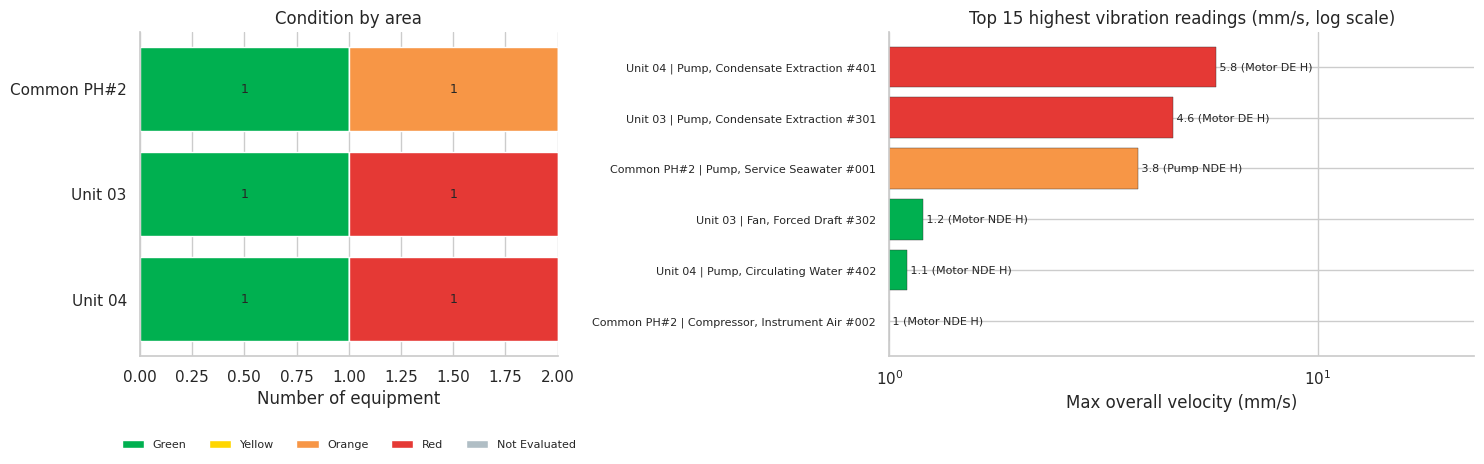

In [30]:
# 3) Charts
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1, 1.4]})

# a) stacked bar – condition per area
s = summary.drop(index="All areas")[CONDITION_ORDER]
left = pd.Series(0, index=s.index)
for cond in CONDITION_ORDER:
    axes[0].barh(s.index, s[cond], left=left, color=COLORS[cond], label=cond, edgecolor="white")
    for i, (l, v) in enumerate(zip(left, s[cond])):
        if v:
            axes[0].text(l + v / 2, i, int(v), ha="center", va="center", fontsize=9)
    left += s[cond]
axes[0].set_title("Condition by area")
axes[0].set_xlabel("Number of equipment")
axes[0].legend(loc="lower center", bbox_to_anchor=(0.5, -0.32), ncol=5, frameon=False, fontsize=8)
axes[0].invert_yaxis()

# b) top 15 highest readings
top = df.dropna(subset=["Max (mm/s)"]).nlargest(15, "Max (mm/s)").iloc[::-1]
labels = top["Area"] + " | " + top["Equipment"]
axes[1].barh(labels, top["Max (mm/s)"], color=[COLORS[c] for c in top["Condition"]], edgecolor="#333", linewidth=0.3)
for y, (v, p) in enumerate(zip(top["Max (mm/s)"], top["Max point"])):
    axes[1].text(v, y, f" {v:g} ({p})", va="center", fontsize=8)
axes[1].set_xscale("log")
axes[1].set_title("Top 15 highest vibration readings (mm/s, log scale)")
axes[1].set_xlabel("Max overall velocity (mm/s)")
axes[1].tick_params(axis="y", labelsize=8)
axes[1].set_xlim(1, top["Max (mm/s)"].max() * 4)

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

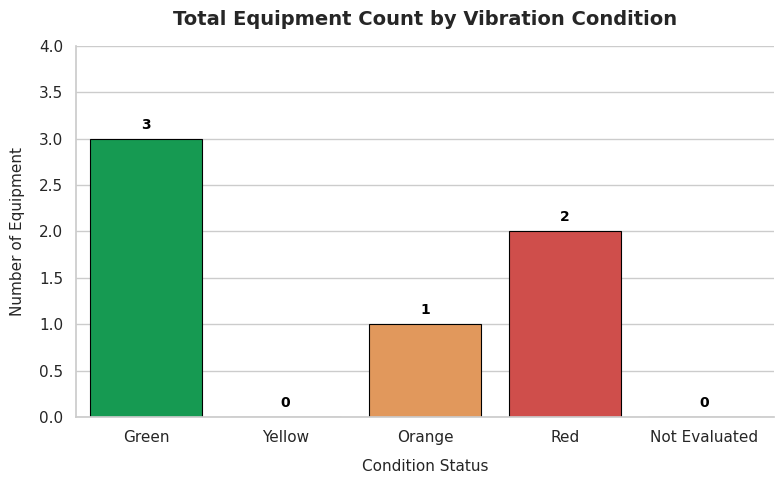

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

# Local definition of colors to prevent NameError
COLORS = {"Green": "#00B050", "Yellow": "#FFD600", "Orange": "#F79646",
          "Red": "#E53935", "Not Evaluated": "#B0BEC5"}

# Count the occurrences of each condition in the main dataframe
condition_counts = df['Condition'].value_counts().reindex(CONDITION_ORDER, fill_value=0).reset_index()
condition_counts.columns = ['Condition', 'Count']

# Set up the visualization style
plt.figure(figsize=(8, 5))
sns.set_theme(style="whitegrid")

# Define hex color palette based on COLORS dictionary
color_palette = [COLORS[cond] for cond in CONDITION_ORDER]

# Create the bar plot
ax = sns.barplot(
    x='Condition',
    y='Count',
    data=condition_counts,
    palette=color_palette,
    hue='Condition',
    legend=False,
    edgecolor='black',
    linewidth=0.8
)

# Add numbers on top of each bar
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=10, fontweight='bold', color='black', xytext=(0, 5),
                textcoords='offset points')

# Set labels and title
plt.title("Total Equipment Count by Vibration Condition", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Condition Status", fontsize=11, labelpad=10)
plt.ylabel("Number of Equipment", fontsize=11, labelpad=10)
plt.ylim(0, condition_counts['Count'].max() + 1)

# Clean styling
sns.despine()
plt.tight_layout()
plt.show()

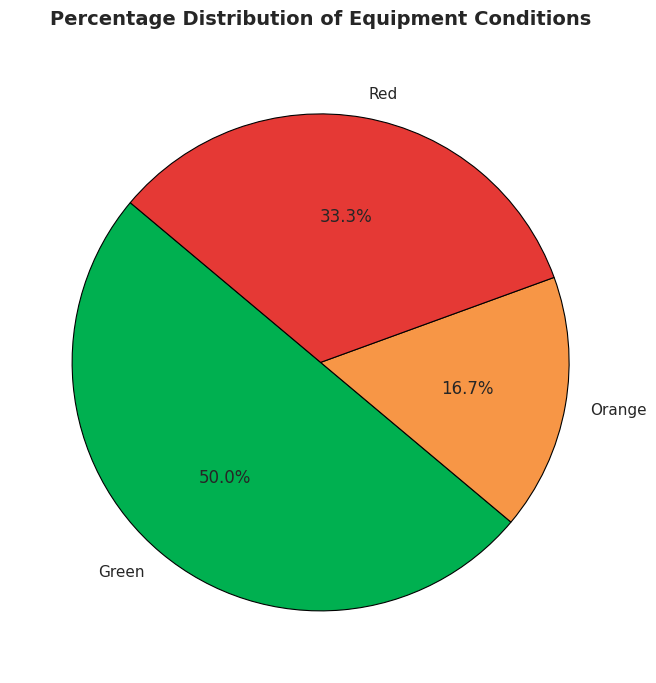

In [32]:
import matplotlib.pyplot as plt

# Prepare data from the main DataFrame
condition_counts = df['Condition'].value_counts().reindex(CONDITION_ORDER, fill_value=0)

# Filter out conditions with 0 count to make the pie chart clean
filtered_counts = condition_counts[condition_counts > 0]

# Map colors dynamically to matching conditions
pie_colors = [COLORS[cond] for cond in filtered_counts.index]

# Create the pie chart
plt.figure(figsize=(7, 7))
plt.pie(
    filtered_counts,
    labels=filtered_counts.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=pie_colors,
    wedgeprops={'edgecolor': 'black', 'linewidth': 0.8, 'antialiased': True}
)

plt.title("Percentage Distribution of Equipment Conditions", fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

### Action list – Red and Orange equipment

In [33]:
# 4) Equipment that needs action, highest vibration first
action = (df[df["Condition"].isin(["Red", "Orange"])]
            .sort_values(["Condition", "Max (mm/s)"], ascending=[False, False])
            [["Area", "Equipment", "Functional Location", "Condition", "Max (mm/s)",
              "Max point", "Finding", "Recommendation"]]
            .reset_index(drop=True))
action.index += 1

def color_row(row):
    return [f"background-color:{COLORS[row['Condition']]}33"] * len(row)

display(action.style.apply(color_row, axis=1).format({"Max (mm/s)": "{:g}"}))
print(f"{len(action)} items need action "
      f"({(action['Condition'] == 'Red').sum()} Red, {(action['Condition'] == 'Orange').sum()} Orange)")

,Area,Equipment,Functional Location,Condition,Max (mm/s),Max point,Finding,Recommendation
1,Unit 04,"Pump, Condensate Extraction #401",04-CE-P401,Red,5.8,Motor DE H,Misalignment on Coupling,Perform precision alignment
2,Unit 03,"Pump, Condensate Extraction #301",03-CE-P301,Red,4.6,Motor DE H,Unbalance on Motor DE,Plan dynamic balancing
3,Common PH#2,"Pump, Service Seawater #001",00-SS-P001,Orange,3.8,Pump NDE H,Bearing wear on Pump NDE,Schedule bearing replacement


3 items need action (2 Red, 1 Orange)


### Search equipment

In [34]:
# 5) Filter: change these values and re-run the cell
AREA = "All"          # "All", "Unit 03", "Unit 04", "Common PH#2"
CONDITION = "All"     # "All", "Green", "Yellow", "Orange", "Red", "Not Evaluated"
KEYWORD = ""          # e.g. "Condensate", "Fan", "W823"

view = df.copy()
if AREA != "All":
    view = view[view["Area"] == AREA]
if CONDITION != "All":
    view = view[view["Condition"] == CONDITION]
if KEYWORD:
    mask = view[["Equipment", "Functional Location", "Finding"]].apply(
        lambda c: c.astype(str).str.contains(KEYWORD, case=False)).any(axis=1)
    view = view[mask]

display(view.drop(columns=["Max point"]).style.apply(color_row, axis=1)
            .format({"Max (mm/s)": lambda v: "" if pd.isna(v) else f"{v:g}"}))
print(f"{len(view)} rows")

,Area,No.,Equipment,Functional Location,Finding,Vibration,Recommendation,Condition,Max (mm/s)
0,Unit 03,1,"Pump, Condensate Extraction #301",03-CE-P301,Unbalance on Motor DE,"Motor NDE H= 1.5 mm/s, Motor DE H= 4.6 mm/s",Plan dynamic balancing,Red,4.6
1,Unit 03,2,"Fan, Forced Draft #302",03-FD-F302,Accepted,"Motor NDE H= 1.2 mm/s, Motor DE H= 1.1 mm/s",Routine monitoring,Green,1.2
2,Unit 04,1,"Pump, Condensate Extraction #401",04-CE-P401,Misalignment on Coupling,"Motor NDE H= 2.1 mm/s, Motor DE H= 5.8 mm/s",Perform precision alignment,Red,5.8
3,Unit 04,2,"Pump, Circulating Water #402",04-CW-P402,Accepted,"Motor NDE H= 1.1 mm/s, Motor DE H= 0.9 mm/s",Routine monitoring,Green,1.1
4,Common PH#2,1,"Pump, Service Seawater #001",00-SS-P001,Bearing wear on Pump NDE,"Pump NDE H= 3.8 mm/s, Pump DE H= 1.8 mm/s",Schedule bearing replacement,Orange,3.8
5,Common PH#2,2,"Compressor, Instrument Air #002",00-IA-C002,Accepted,"Motor NDE H= 1.0 mm/s, Motor DE H= 0.8 mm/s",Routine monitoring,Green,1


6 rows


## Advanced reliability analysis
This section turns the report into reliability decisions:

1. **ISO 20816 zone check.** Each measured value is classified into zones A/B/C/D and compared with the report colour.
2. **Fault-mode Pareto.** It shows which failure mechanisms drive the bad actors.
3. **Criticality × severity risk matrix.** It produces a risk score and a maintenance priority (P1–P4).
4. **Redundancy / standby check.** It flags systems where the duty and standby trains are both degraded.
5. **Area health index** (0–100) and evaluation coverage.

> ⚙️ The ISO limits and the criticality ranking below are **editable assumptions**. Adjust them to your machine classes and plant criticality register, then re-run.

In [35]:
# 7) Settings – edit to match your plant
# ISO 20816-3 velocity zone limits (mm/s RMS), Group 2 machines (15-300 kW).
# Rigid foundation: A/B=1.4, B/C=2.8, C/D=4.5 | Flexible foundation: 2.3 / 4.5 / 7.1
FOUNDATION = "rigid"     # "rigid" or "flexible"
ISO_LIMITS = {"rigid": (1.4, 2.8, 4.5), "flexible": (2.3, 4.5, 7.1)}[FOUNDATION]

# Equipment criticality (A = high, B = medium, C = low): first keyword match wins
CRITICALITY_RULES = [
    ("condensate extraction", "A"), ("circulating water", "A"), ("forced draft", "A"),
    ("preheater", "A"), ("jacking oil", "A"), ("emergency oil", "A"), ("seal oil", "A"),
    ("auxiliary oil", "A"), ("turning oil", "A"), ("fuel oil", "B"),
    ("gas recirculation", "B"), ("air extraction", "B"), ("heater drain", "B"),
    ("service seawater", "B"), ("closed circuit cooling", "B"), ("bearing & seal water", "B"),
    ("flame scanner", "B"), ("ignitor booster", "C"), ("screen wash", "C"),
    ("steam condenser exhauster", "C"),
]
CRIT_WEIGHT = {"A": 3, "B": 2, "C": 1}
SEVERITY = {"Green": 1, "Yellow": 2, "Orange": 3, "Red": 4, "Not Evaluated": 2}  # unknown = medium

FAULT_RULES = [   # keyword in Finding -> fault mode
    ("vane pass", "Vane pass / hydraulic"), ("van pass", "Vane pass / hydraulic"),
    ("flow turbulence", "Flow turbulence"), ("misalignment", "Misalignment"),
    ("alignment", "Misalignment"), ("coupling", "Coupling fault"),
    ("unbalance", "Unbalance"), ("looseness", "Looseness"),
    ("bearing", "Bearing fault"), ("screw mesh", "Gear / screw mesh"),
]

In [36]:
# Calculate total equipment count grouped by Area and Condition
counts_by_area_condition = df.groupby(['Area', 'Condition'], observed=False).size().reset_index(name='Total Equipment')
display(counts_by_area_condition)

,Area,Condition,Total Equipment
0,Common PH#2,Green,1
1,Common PH#2,Yellow,0
2,Common PH#2,Orange,1
3,Common PH#2,Red,0
4,Common PH#2,Not Evaluated,0
5,Unit 03,Green,1
6,Unit 03,Yellow,0
7,Unit 03,Orange,0
8,Unit 03,Red,1
9,Unit 03,Not Evaluated,0


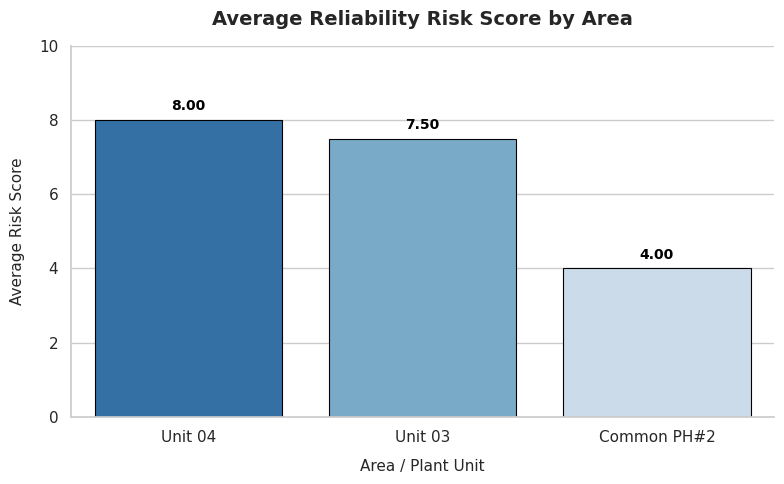

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import re

# Safely define 'rel' locally if it hasn't been initialized yet
if 'rel' not in globals():
    def iso_zone(v):
        if pd.isna(v):
            return "n/a"
        a, b, c = ISO_LIMITS
        return "A" if v <= a else "B" if v <= b else "C" if v <= c else "D"

    ZONE_OK_COLORS = {"A": {"Green"}, "B": {"Green", "Yellow"}, "C": {"Yellow", "Orange"}, "D": {"Orange", "Red"}}
    ZONE_RANK = {"Green": 1, "Yellow": 2, "Orange": 3, "Red": 4}

    def criticality(name):
        n = name.lower().replace(",", " ")
        n = " ".join(n.split())
        for kw, c in CRITICALITY_RULES:
            if kw in n:
                return c
        return "B"

    def fault_modes(finding):
        f = str(finding).lower()
        if f in ("accepted", "not evaluated", "nan"):
            return []
        modes = []
        for kw, mode in FAULT_RULES:
            if kw in f and mode not in modes:
                modes.append(mode)
        if not modes and "vibration" in f:
            modes = ["High vibration (root cause TBD)"]
        return modes

    def system_key(row):
        base = re.sub(r"[#\d.]+", " ", row["Equipment"])
        base = re.sub(r"[,]+", " ", base)
        base = re.sub(r"\b(Vertical|Mt)\b", " ", base, flags=re.I)
        return f"{row['Area']} | " + " ".join(base.split()).title()

    rel = df.copy()
    rel["ISO zone"] = rel["Max (mm/s)"].apply(iso_zone)
    rel["Criticality"] = rel["Equipment"].apply(criticality)
    rel["Fault modes"] = rel["Finding"].apply(fault_modes)
    rel["System"] = rel.apply(system_key, axis=1)
    rel["Severity"] = rel["Condition"].astype(str).map(SEVERITY)

    def iso_check(r):
        if r["ISO zone"] == "n/a":
            return "Not measured"
        cond = str(r["Condition"])
        if cond in ZONE_OK_COLORS[r["ISO zone"]]:
            return "Consistent"
        if ZONE_RANK.get(cond, 0) < min(ZONE_RANK[c] for c in ZONE_OK_COLORS[r["ISO zone"]]):
            return "ISO worse than report"
        return "Report worse than ISO (spectrum-based)"
    rel["ISO check"] = rel.apply(iso_check, axis=1)

    healthy = rel["Condition"].isin(["Green", "Yellow"])
    sys_stats_local = rel.groupby("System").agg(Units=("No.", "count"),
                                          Healthy=("Condition", lambda s: s.isin(["Green", "Yellow"]).sum()))
    rel = rel.merge(sys_stats_local[["Units", "Healthy"]], left_on="System", right_index=True)
    rel["No healthy standby"] = (rel["Condition"].isin(["Orange", "Red"]) & (rel["Units"] > 1) & (rel["Healthy"] == 0))
    rel["Risk score"] = (rel["Severity"] * rel["Criticality"].map(CRIT_WEIGHT)
                         + 2 * rel["No healthy standby"]
                         + rel["Fault modes"].apply(lambda m: max(len(m) - 1, 0)))

# Calculate average Risk Score by Area
area_risk = rel.groupby('Area', observed=False)['Risk score'].mean().reset_index()

# Sort for better visualization
area_risk = area_risk.sort_values(by='Risk score', ascending=False)

plt.figure(figsize=(8, 5))
sns.set_theme(style='whitegrid')

# Create bar plot
ax = sns.barplot(
    x='Area',
    y='Risk score',
    data=area_risk,
    palette='Blues_r',
    hue='Area',
    legend=False,
    edgecolor='black',
    linewidth=0.8
)

# Add values on top of the bars
for p in ax.patches:
    ax.annotate(f'{p.get_height():.2f}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=10, fontweight='bold', color='black', xytext=(0, 5),
                textcoords='offset points')

plt.title('Average Reliability Risk Score by Area', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Area / Plant Unit', fontsize=11, labelpad=10)
plt.ylabel('Average Risk Score', fontsize=11, labelpad=10)
plt.ylim(0, area_risk['Risk score'].max() + 2)

sns.despine()
plt.tight_layout()
plt.show()

In [38]:
# 8) Reliability model
import numpy as np

def iso_zone(v):
    if pd.isna(v):
        return "n/a"
    a, b, c = ISO_LIMITS
    return "A" if v <= a else "B" if v <= b else "C" if v <= c else "D"

# report colours that are consistent with each ISO zone
ZONE_OK_COLORS = {"A": {"Green"}, "B": {"Green", "Yellow"}, "C": {"Yellow", "Orange"}, "D": {"Orange", "Red"}}
ZONE_RANK = {"Green": 1, "Yellow": 2, "Orange": 3, "Red": 4}
ZONE_NUM = {"A": 1, "B": 2, "C": 3, "D": 4}

def criticality(name):
    n = name.lower().replace(",", " ")
    n = " ".join(n.split())
    for kw, c in CRITICALITY_RULES:
        if kw in n:
            return c
    return "B"

def fault_modes(finding):
    f = str(finding).lower()
    if f in ("accepted", "not evaluated", "nan"):
        return []
    modes = []
    for kw, mode in FAULT_RULES:
        if kw in f and mode not in modes:
            modes.append(mode)
    if not modes and "vibration" in f:
        modes = ["High vibration (root cause TBD)"]
    return modes

def system_key(row):
    # "Pump, Condensate Extraction #401" -> "Unit 04 | Pump Condensate Extraction"
    base = re.sub(r"[#\d.]+", " ", row["Equipment"])
    base = re.sub(r"[,]+", " ", base)
    base = re.sub(r"\b(Vertical|Mt)\b", " ", base, flags=re.I)
    return f"{row['Area']} | " + " ".join(base.split()).title()

rel = df.copy()
rel["ISO zone"] = rel["Max (mm/s)"].apply(iso_zone)
rel["Criticality"] = rel["Equipment"].apply(criticality)
rel["Fault modes"] = rel["Finding"].apply(fault_modes)
rel["System"] = rel.apply(system_key, axis=1)
rel["Severity"] = rel["Condition"].astype(str).map(SEVERITY)

# ISO check vs the report colour
def iso_check(r):
    if r["ISO zone"] == "n/a":
        return "Not measured"
    cond = str(r["Condition"])
    if cond in ZONE_OK_COLORS[r["ISO zone"]]:
        return "Consistent"
    # report colour lower than the zone allows -> overall level is worse than the report says
    if ZONE_RANK.get(cond, 0) < min(ZONE_RANK[c] for c in ZONE_OK_COLORS[r["ISO zone"]]):
        return "ISO worse than report"
    return "Report worse than ISO (spectrum-based)"
rel["ISO check"] = rel.apply(iso_check, axis=1)

# Redundancy: how many units in the same system are healthy (Green/Yellow)?
healthy = rel["Condition"].isin(["Green", "Yellow"])
sys_stats = rel.groupby("System").agg(Units=("No.", "count"),
                                      Healthy=("Condition", lambda s: s.isin(["Green", "Yellow"]).sum()),
                                      Degraded=("Condition", lambda s: s.isin(["Orange", "Red"]).sum()),
                                      Not_evaluated=("Condition", lambda s: (s == "Not Evaluated").sum()))
rel = rel.merge(sys_stats[["Units", "Healthy"]], left_on="System", right_index=True)
# penalty when a degraded machine has no healthy standby in its system
rel["No healthy standby"] = (rel["Condition"].isin(["Orange", "Red"]) & (rel["Units"] > 1)
                             & (rel["Healthy"] == 0))

# Risk score = severity x criticality weight (+2 if no healthy standby, +1 per extra fault mode)
rel["Risk score"] = (rel["Severity"] * rel["Criticality"].map(CRIT_WEIGHT)
                     + 2 * rel["No healthy standby"]
                     + rel["Fault modes"].apply(lambda m: max(len(m) - 1, 0)))

def priority(r):
    if r["Condition"] == "Not Evaluated":
        return "Survey" if r["Criticality"] != "C" else "P4"
    s = r["Risk score"]
    return "P1" if s >= 10 else "P2" if s >= 6 else "P3" if s >= 3 else "P4"
rel["Priority"] = rel.apply(priority, axis=1)
PRIORITY_TEXT = {
    "P1": "Immediate – fix during this T&I",
    "P2": "High – plan within T&I scope / next window",
    "P3": "Monitor – shorten route interval",
    "P4": "Routine monitoring",
    "Survey": "Collect baseline before return to service",
}
rel["Action window"] = rel["Priority"].map(PRIORITY_TEXT)
print(rel["Priority"].value_counts().reindex(["P1", "P2", "P3", "P4", "Survey"], fill_value=0).to_string())

Priority
P1        2
P2        1
P3        2
P4        1
Survey    0


### Reliability dashboard

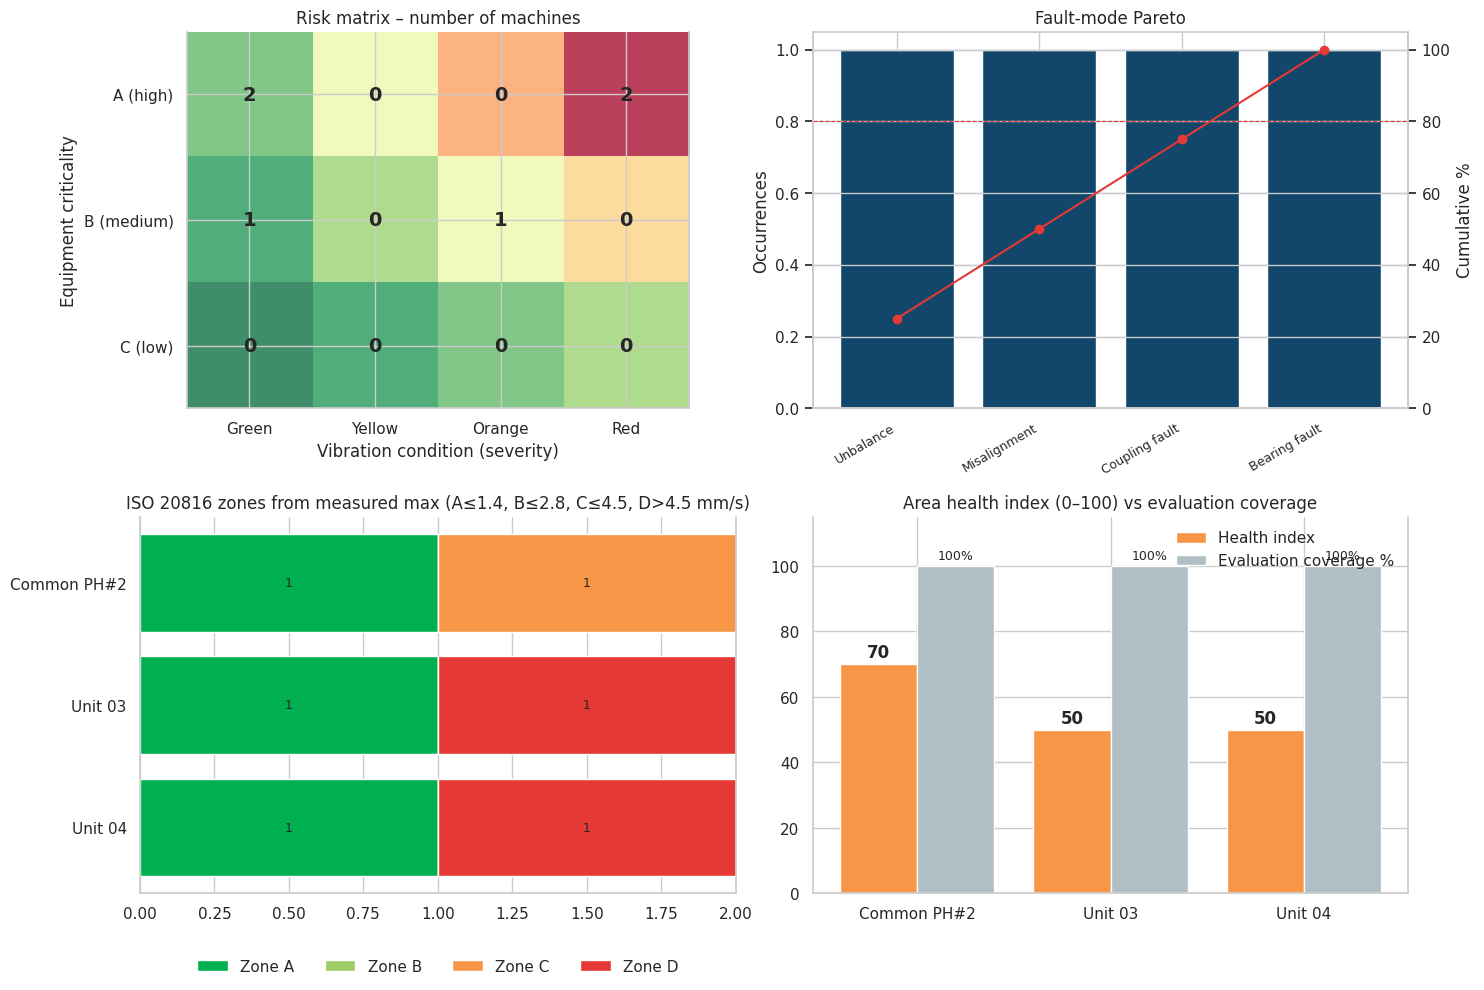

In [39]:
# 9) Charts: risk matrix, fault Pareto, ISO zones, area health index
fig, ax = plt.subplots(2, 2, figsize=(15, 10))

# a) Risk matrix: criticality x condition
mat = (rel[rel["Condition"] != "Not Evaluated"]
       .pivot_table(index="Criticality", columns="Condition", values="No.", aggfunc="count",
                    fill_value=0, observed=False)
       .reindex(index=["A", "B", "C"], columns=["Green", "Yellow", "Orange", "Red"], fill_value=0))
risk = np.outer([3, 2, 1], [1, 2, 3, 4])
ax[0, 0].imshow(risk, cmap="RdYlGn_r", alpha=0.75, vmin=1, vmax=12)
for i in range(3):
    for j in range(4):
        ax[0, 0].text(j, i, int(mat.iloc[i, j]), ha="center", va="center", fontsize=14, fontweight="bold")
ax[0, 0].set_xticks(range(4), ["Green", "Yellow", "Orange", "Red"])
ax[0, 0].set_yticks(range(3), ["A (high)", "B (medium)", "C (low)"])
ax[0, 0].set_xlabel("Vibration condition (severity)")
ax[0, 0].set_ylabel("Equipment criticality")
ax[0, 0].set_title("Risk matrix – number of machines")

# b) Fault mode Pareto
fm = rel.explode("Fault modes").dropna(subset=["Fault modes"])["Fault modes"].value_counts()
cum = fm.cumsum() / fm.sum() * 100
ax[0, 1].bar(fm.index, fm.values, color="#12476b")
ax[0, 1].set_xticks(range(len(fm)), fm.index, rotation=30, ha="right", fontsize=9)
ax[0, 1].set_ylabel("Occurrences")
ax2 = ax[0, 1].twinx()
ax2.plot(fm.index, cum.values, color="#E53935", marker="o")
ax2.axhline(80, color="#E53935", ls="--", lw=0.8)
ax2.set_ylim(0, 105)
ax2.set_ylabel("Cumulative %")
ax[0, 1].set_title("Fault-mode Pareto")

# c) ISO zone distribution per area
zones = (rel[rel["ISO zone"] != "n/a"].pivot_table(index="Area", columns="ISO zone", values="No.",
         aggfunc="count", fill_value=0).reindex(columns=list("ABCD"), fill_value=0))
zc = {"A": "#00B050", "B": "#9CCC65", "C": "#F79646", "D": "#E53935"}
left = pd.Series(0, index=zones.index)
for z in "ABCD":
    ax[1, 0].barh(zones.index, zones[z], left=left, color=zc[z], label=f"Zone {z}", edgecolor="white")
    for i, (l, v) in enumerate(zip(left, zones[z])):
        if v:
            ax[1, 0].text(l + v / 2, i, int(v), ha="center", va="center", fontsize=9)
    left += zones[z]
a, b, c = ISO_LIMITS
ax[1, 0].set_title(f"ISO 20816 zones from measured max (A≤{a}, B≤{b}, C≤{c}, D>{c} mm/s)")
ax[1, 0].legend(ncol=4, loc="lower center", bbox_to_anchor=(0.5, -0.25), frameon=False)
ax[1, 0].invert_yaxis()

# d) Area health index (evaluated machines, Green=100, Yellow=70, Orange=40, Red=0)
HI = {"Green": 100, "Yellow": 70, "Orange": 40, "Red": 0}
ev = rel[rel["Condition"] != "Not Evaluated"].copy()
ev["HI"] = ev["Condition"].astype(str).map(HI)
health = ev.groupby("Area")["HI"].mean()
coverage = rel.groupby("Area")["Condition"].apply(lambda s: (s != "Not Evaluated").mean() * 100)
x = np.arange(len(health))
bars = ax[1, 1].bar(x - 0.2, health.values, 0.4, label="Health index",
                    color=[("#00B050" if h >= 75 else "#F79646" if h >= 50 else "#E53935") for h in health])
ax[1, 1].bar(x + 0.2, coverage.reindex(health.index).values, 0.4, label="Evaluation coverage %", color="#B0BEC5")
for xi, h, cv in zip(x, health.values, coverage.reindex(health.index).values):
    ax[1, 1].text(xi - 0.2, h + 2, f"{h:.0f}", ha="center", fontweight="bold")
    ax[1, 1].text(xi + 0.2, cv + 2, f"{cv:.0f}%", ha="center", fontsize=9)
ax[1, 1].set_xticks(x, health.index)
ax[1, 1].set_ylim(0, 115)
ax[1, 1].set_title("Area health index (0–100) vs evaluation coverage")
ax[1, 1].legend(frameon=False, loc="upper right")

for a_ in ax.flat:
    a_.spines[["top"]].set_visible(False)
plt.tight_layout()
plt.show()

### Maintenance priority list

In [40]:
# 10) Ranked work list (highest risk first)
PRI_COLORS = {"P1": "#E53935", "P2": "#F79646", "P3": "#FFD600", "P4": "#00B050", "Survey": "#B0BEC5"}
work = (rel.sort_values(["Risk score", "Max (mm/s)"], ascending=False)
          [["Priority", "Risk score", "Area", "Equipment", "Criticality", "Condition", "ISO zone",
            "Max (mm/s)", "Max point", "Fault modes", "No healthy standby", "Recommendation", "Action window"]]
          .reset_index(drop=True))
work["Fault modes"] = work["Fault modes"].apply(lambda m: ", ".join(m))
work.index += 1

def pri_style(row):
    return [f"background-color:{PRI_COLORS[row['Priority']]}33"] * len(row)

display(work[work["Priority"].isin(["P1", "P2"])].style.apply(pri_style, axis=1)
        .format({"Max (mm/s)": lambda v: "" if pd.isna(v) else f"{v:g}"}))

,Priority,Risk score,Area,Equipment,Criticality,Condition,ISO zone,Max (mm/s),Max point,Fault modes,No healthy standby,Recommendation,Action window
1,P1,13,Unit 04,"Pump, Condensate Extraction #401",A,Red,D,5.8,Motor DE H,"Misalignment, Coupling fault",False,Perform precision alignment,Immediate – fix during this T&I
2,P1,12,Unit 03,"Pump, Condensate Extraction #301",A,Red,D,4.6,Motor DE H,Unbalance,False,Plan dynamic balancing,Immediate – fix during this T&I
3,P2,6,Common PH#2,"Pump, Service Seawater #001",B,Orange,C,3.8,Pump NDE H,Bearing fault,False,Schedule bearing replacement,High – plan within T&I scope / next window


In [45]:
# Filter and display equipment requiring Immediate action (Priority P1)
immediate_action = work[work['Priority'] == 'P1']

print(f"Found {len(immediate_action)} equipment item(s) requiring 'Immediate' action:")
display(immediate_action.style.apply(pri_style, axis=1).format({"Max (mm/s)": lambda v: "" if pd.isna(v) else f"{v:g}"}))

Found 2 equipment item(s) requiring 'Immediate' action:


,Priority,Risk score,Area,Equipment,Criticality,Condition,ISO zone,Max (mm/s),Max point,Fault modes,No healthy standby,Recommendation,Action window
1,P1,13,Unit 04,"Pump, Condensate Extraction #401",A,Red,D,5.8,Motor DE H,"Misalignment, Coupling fault",False,Perform precision alignment,Immediate – fix during this T&I
2,P1,12,Unit 03,"Pump, Condensate Extraction #301",A,Red,D,4.6,Motor DE H,Unbalance,False,Plan dynamic balancing,Immediate – fix during this T&I


In [41]:
# 11) Systems with no healthy standby + ISO / report disagreements
redund = sys_stats[(sys_stats["Units"] > 1) & (sys_stats["Healthy"] == 0) & (sys_stats["Degraded"] > 0)]
print("⚠️ Systems where NO unit is healthy (Green/Yellow) – loss of redundancy:")
display(redund.rename(columns={"Not_evaluated": "Not evaluated"}))

mism = rel[rel["ISO check"].isin(["ISO worse than report", "Report worse than ISO (spectrum-based)"])]
print("\n🔎 Machines where the ISO zone and the report colour disagree (review these):")
if mism.empty:
    print("None – every measured value is consistent with its report colour.")
else:
    display(mism[["Area", "Equipment", "Condition", "ISO zone", "Max (mm/s)", "Max point", "ISO check", "Finding"]]
            .reset_index(drop=True))

⚠️ Systems where NO unit is healthy (Green/Yellow) – loss of redundancy:


,Units,Healthy,Degraded,Not evaluated
System,,,,



🔎 Machines where the ISO zone and the report colour disagree (review these):
None – every measured value is consistent with its report colour.


In [42]:
# 12) Reliability KPIs and executive summary
n = len(rel)
n_eval = int((rel["Condition"] != "Not Evaluated").sum())
n_bad = int(rel["Condition"].isin(["Orange", "Red"]).sum())
kpi = {
    "Evaluation coverage": f"{n_eval / n:.0%}",
    "Healthy (Green/Yellow) of evaluated": f"{rel['Condition'].isin(['Green', 'Yellow']).sum() / n_eval:.0%}",
    "Bad actors (Orange/Red)": n_bad,
    "Critical (A) bad actors": int((rel["Condition"].isin(["Orange", "Red"]) & (rel["Criticality"] == "A")).sum()),
    "P1 work orders": int((rel["Priority"] == "P1").sum()),
    "Systems without healthy standby": len(redund),
}
cards = "".join(
    f"<div style='background:#ffffff14;border:1px solid #ffffff26;border-radius:10px;padding:12px 16px;min-width:170px'>"
    f"<div style='font-size:11px;letter-spacing:1px;text-transform:uppercase;color:#9fd8d2'>{k}</div>"
    f"<div style='font-size:24px;font-weight:700;margin-top:4px'>{v}</div></div>" for k, v in kpi.items())
top_fault = fm.index[0] if len(fm) else "-"
worst_area = health.idxmin()
p1 = work[work["Priority"] == "P1"]
bullets = "".join(f"<li>{r['Area']} – {r['Equipment']} ({r['Max (mm/s)']:g} mm/s, {r['Condition']})</li>"
                  for _, r in p1.head(5).iterrows())
display(HTML(f"""<div style='font-family:Segoe UI,Arial,sans-serif;background:linear-gradient(135deg,#0b1f33,#12476b);
color:#fff;border-radius:14px;padding:22px 26px'>
<div style='font-size:12px;letter-spacing:2px;color:#9fd8d2'>RELIABILITY SUMMARY – BEFORE T&I</div>
<div style='display:flex;flex-wrap:wrap;gap:12px;margin:14px 0'>{cards}</div>
<div style='font-size:14px;line-height:1.6'>
<b>Lowest health:</b> {worst_area} (index {health.min():.0f}/100) &nbsp;|&nbsp;
<b>Dominant fault mode:</b> {top_fault} &nbsp;|&nbsp;
<b>Not evaluated:</b> {n - n_eval} machines need a baseline before start-up.<br>
<b>Top P1 items:</b><ol style='margin:6px 0 0'>{bullets}</ol></div></div>"""))

In [43]:
# 13) Export everything to Excel (downloads in Colab)
OUT = "Vibration_Analysis_Before_TI.xlsx"
export = rel.copy()
export["Fault modes"] = export["Fault modes"].apply(lambda m: ", ".join(m))
with pd.ExcelWriter(OUT) as xw:
    summary.to_excel(xw, sheet_name="Summary")
    work.to_excel(xw, sheet_name="Priority work list")
    action.to_excel(xw, sheet_name="Action list")
    sys_stats.to_excel(xw, sheet_name="Redundancy")
    mism.drop(columns=["Fault modes"]).to_excel(xw, sheet_name="ISO vs report", index=False)
    export.to_excel(xw, sheet_name="All equipment", index=False)
print("Saved", OUT)
try:
    from google.colab import files
    files.download(OUT)
except ImportError:
    pass

Saved Vibration_Analysis_Before_TI.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [44]:
import pandas as pd

# Export the processed main DataFrame to a new Excel file
export_filename = 'Processed_Vibration_Reports.xlsx'
df.to_excel(export_filename, index=False, sheet_name='All_Equipment')
print(f'Processed data successfully exported and saved as: {export_filename}')

# Attempt to download the file directly in Google Colab
try:
    from google.colab import files
    files.download(export_filename)
except ImportError:
    pass

Processed data successfully exported and saved as: Processed_Vibration_Reports.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>